1. Ensuring Data Consistency

To compare models fairly, they must all train and evaluate on the exact same data. Any difference in the split — different random seed, different proportions — would introduce noise that is indistinguishable from actual model quality differences.

In [42]:
from wrangle import clean_files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import make_pipeline
from category_encoders import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression,RidgeCV,LassoCV


### Get data

In [4]:
#load data
df=clean_files("../data/buenos-aires-real-estate-*.csv")

# define target and feature
target="price_aprox_usd"
features=[col for col in df.columns.tolist() if col not in target ]

#split target and features
y=df[target]
X=df[features]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (6247, 4)
Target shape: (6247,)


### Split train and test data

In [8]:
X_train_4,X_test_4,y_train_4,y_test_4=train_test_split(X,y,test_size=0.2,random_state=42)

print(f"X_train: {X_train_4.shape}")

print(f"X_test: {X_test_4.shape}")

print(f"y_train: {y_train_4.shape}")

print(f"y_test: {y_test_4.shape}")

X_train: (4997, 4)
X_test: (1250, 4)
y_train: (4997,)
y_test: (1250,)


### calculate rmse

In [10]:
def get_rmse_4(model,X,y_true):
    y_pred=model.predict(X)
    rmse=root_mean_squared_error(y_true,y_pred)
    return rmse
# Test the function
print("Function created successfully!")


Function created successfully!


### Baseline

In [14]:
y_mean_4=y_train_4.mean()

# create baseline prediction
y_pred_baseline_train=[y_mean_4]*len(y_train_4)
y_pred_baseline_test=[y_mean_4] * len(y_test_4)

# calculate rmse
rmse_base_train=root_mean_squared_error(y_train_4,y_pred_baseline_train)
rmse_base_test=root_mean_squared_error(y_test_4,y_pred_baseline_test)

print(f"Baseline Train RMSE: ${rmse_base_train:,.2f}")
print(f"Baseline Test RMSE: ${rmse_base_test:,.2f}")

Baseline Train RMSE: $59,055.77
Baseline Test RMSE: $60,168.35


### line regression

In [18]:
model_linear_4=make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LinearRegression()
)
model_linear_4.fit(X_train_4,y_train_4)

rmse_linear_train=get_rmse_4(model_linear_4,X_train_4,y_train_4)
rmse_linear_test=get_rmse_4(model_linear_4,X_test_4,y_test_4)

print(f"Linear Regression Train RMSE: ${rmse_linear_train:,.2f}")
print(f"Linear Regression Test RMSE: ${rmse_linear_test:,.2f}")

Linear Regression Train RMSE: $33,789.98
Linear Regression Test RMSE: $34,700.07


### Ridge regression

In [25]:
model_ridge_4=make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-2,4,100))
    
)
model_ridge_4.fit(X_train_4,y_train_4)
rmse_train_ridge=get_rmse_4(model_ridge_4,X_train_4,y_train_4)
rmse_test_ridge=get_rmse_4(model_ridge_4,X_test_4,y_test_4)

alpha_ridge_chosen=model_ridge_4.named_steps["ridgecv"].alpha_

print(f"Best ridge alpha:{alpha_ridge_chosen:,.6f}")

print(f"Ridge Train RMSE ${rmse_train_ridge:,.2f}")
print(f"Ridge Test RMSE ${rmse_test_ridge:,.2f}")


Best ridge alpha:43.287613
Ridge Train RMSE $33,793.16
Ridge Test RMSE $34,701.13


### lasso regression

In [30]:
model_lasso_4=make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas=np.logspace(-4,2,100),max_iter=10000)
)
model_lasso_4.fit(X_train_4,y_train_4)

rmse_lasso_train=get_rmse_4(model_lasso_4,X_train_4,y_train_4)
rmse_lasso_test=get_rmse_4(model_lasso_4,X_test_4,y_test_4)

# extract the chosen alpha
alpha_lasso_chosen=model_lasso_4.named_steps["lassocv"].alpha_
print(f"Best Lasso alpha: {alpha_lasso_chosen:.6f}")
print(f"Lasso Train RMSE: ${rmse_lasso_train:,.2f}")
print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")

Best Lasso alpha: 100.000000
Lasso Train RMSE: $33,806.62
Lasso Test RMSE: $34,687.48


### Unified comparison table
A unified comparison table is the standard tool for model selection. It places all candidates side by side on the metrics that matter, making the selection decision explicit and auditable.

In [34]:
data_4={
    "Model":["Baseline","Linear Regression","Ridge (CV-tuned)","Lasso ( CV-tuned)"],
    "Train_RMSE":[rmse_base_train,rmse_linear_train,rmse_train_ridge,rmse_lasso_train],
    "Test_RMSE":[rmse_base_test,rmse_linear_test,rmse_test_ridge,rmse_lasso_test]
}
df_result_4=pd.DataFrame(data_4)
df_result_4

,Model,Train_RMSE,Test_RMSE
0,Baseline,59055.772180,60168.349672
1,Linear Regression,33789.975401,34700.069251
2,Ridge (CV-tuned),33793.162286,34701.131341
3,Lasso ( CV-tuned),33806.617640,34687.476265


In [35]:
df_result_4["Gap"]=df_result_4["Test_RMSE"]-df_result_4["Train_RMSE"]
df_result_4

,Model,Train_RMSE,Test_RMSE,Gap
0,Baseline,59055.772180,60168.349672,1112.577491
1,Linear Regression,33789.975401,34700.069251,910.093850
2,Ridge (CV-tuned),33793.162286,34701.131341,907.969055
3,Lasso ( CV-tuned),33806.617640,34687.476265,880.858625


In [ ]:
df_result_4=df_result_4.set_index("Model")
df_result_4

In [39]:
df_result_4

,Train_RMSE,Test_RMSE,Gap
Model,,,
Baseline,59055.772180,60168.349672,1112.577491
Linear Regression,33789.975401,34700.069251,910.093850
Ridge (CV-tuned),33793.162286,34701.131341,907.969055
Lasso ( CV-tuned),33806.617640,34687.476265,880.858625


In [41]:
print("\n" + "="*60)
print("MODEL COMPARISON TABLE")
print("="*60)
print(df_result_4.round(2))
print("="*60)


MODEL COMPARISON TABLE
                   Train_RMSE  Test_RMSE      Gap
Model                                            
Baseline             59055.77   60168.35  1112.58
Linear Regression    33789.98   34700.07   910.09
Ridge (CV-tuned)     33793.16   34701.13   907.97
Lasso ( CV-tuned)    33806.62   34687.48   880.86


### Visualize perfomnce

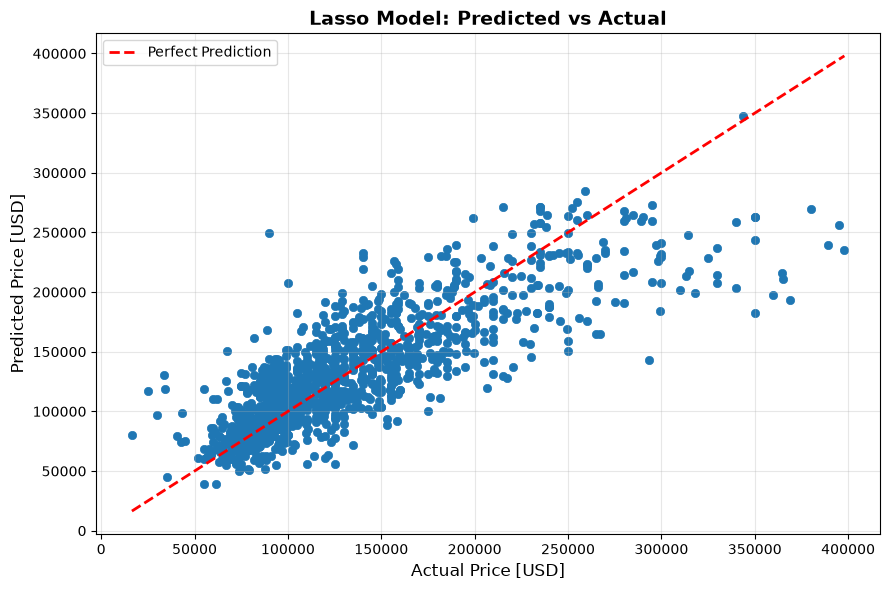

In [46]:
y_pred_lasso=model_lasso_4.predict(X_test_4)

fig,ax=plt.subplots(figsize=(9,6))
ax.scatter(y_test_4,y_pred_lasso,linewidths=0.5)
ideal_line=np.linspace(y_test_4.min(),y_test_4.max(),100)
ax.plot(ideal_line,ideal_line, color="red",linestyle="--",linewidth=2,label="Perfect Prediction")

ax.set_xlabel("Actual Price [USD]",fontsize=12)
ax.set_ylabel("Predicted Price [USD]",fontsize=12)
ax.set_title("Lasso Model: Predicted vs Actual",fontsize=14,fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

### Residual analysis

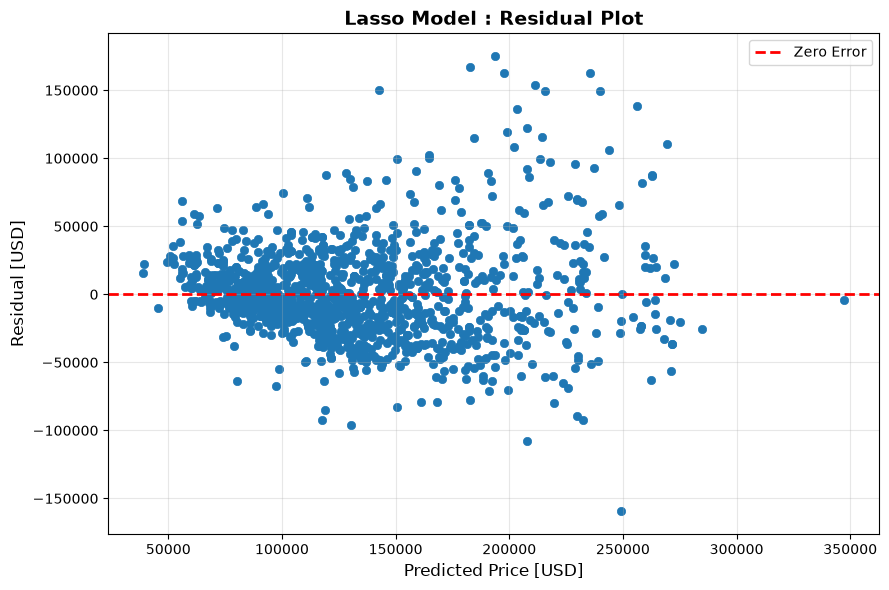

In [51]:
residuals_4=y_test_4-y_pred_lasso
fig_res,ax_res=plt.subplots(figsize=(9,6))
ax_res.scatter(y_pred_lasso,residuals_4,linewidth=0.5)
ax_res.axhline(y=0,color="red",linestyle="--",linewidth=2,label="Zero Error")
ax_res.set_xlabel("Predicted Price [USD]",fontsize=12)
ax_res.set_ylabel("Residual [USD]",fontsize=12)
ax_res.set_title("Lasso Model : Residual Plot",fontsize=14,fontweight='bold')
ax_res.legend(fontsize=10)
ax_res.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

**Heteroscedasticity** means that the errors (residuals) of a regression model have unequal variance across different predicted values or levels of the input variables.
In simple terms, the model's prediction errors become more spread out in some areas than others.

![Heteroscedasticity](../image/Screenshot%202026-10-14%20at%2008.24.15.png)

## Heteroscedasticity: Impact on Model Reliability

**Meaning:** Heteroscedasticity occurs when the variance of regression errors is not constant across different predicted values.

### 1. Impact on Reliability
- **Biased standard errors:** In ordinary least squares (OLS), the usual standard errors may be incorrect, making confidence intervals and hypothesis tests unreliable.
- **Unreliable prediction intervals:** Predictions for expensive properties may have much wider errors than expected.
- **RMSE limitation:** Overall RMSE can hide the fact that prediction errors are larger for expensive properties.

### 2. Implications for Deployment
- The model may be more reliable for typical, mid-range apartments where training data is concentrated.
- Luxury properties may have substantially larger prediction errors.
- Users should be informed of this limitation before relying on predictions.

### 3. Can Heteroscedasticity Be Reduced?
- **Log-transform the target:** Use `np.log(price)` to potentially reduce unequal error variance by modeling prices on a logarithmic scale. Predictions must be transformed back using `np.exp()`.
- **Try nonlinear models:** Random Forest and XGBoost may capture complex pricing patterns that linear regression misses.
- **Evaluate again:** Check residual plots and compare performance across different price ranges.

**Key takeaway:** A low overall RMSE does not guarantee equally reliable predictions for every property. Always investigate how errors vary across the target range.

## the lasso advantage

In [55]:
coef_4=model_lasso_4.named_steps["lassocv"].coef_
feature_names_4=model_lasso_4.named_steps["onehotencoder"].get_feature_names_out()
feat_imp_4=pd.Series(coef_4,index=feature_names_4)
feat_imp_4
print(f"Total features: {len(feat_imp_4)}")
print(f"Non-zero features: {(feat_imp_4 != 0).sum()}")
print("\nTop 5 positive coefficients:")
print(feat_imp_4.nlargest(5))
print("\nTop 5 negative coefficients:")
print(feat_imp_4.nsmallest(5))

Total features: 59
Non-zero features: 55

Top 5 positive coefficients:
surface_covered_in_m2         40008.412079
neighborhood_Palermo          10649.663494
neighborhood_Puerto Madero    10268.306843
lat                            7936.778499
neighborhood_Belgrano          7568.882202
dtype: float64

Top 5 negative coefficients:
neighborhood_Balvanera      -4663.298189
neighborhood_Boca           -4435.509944
neighborhood_Once           -4127.456400
neighborhood_Congreso       -2825.321731
neighborhood_Villa Lugano   -2606.604591
dtype: float64
